# 03 core 피처 13개 점검

- `src/features.py`로 150행 × 13열 피처 표를 만든다
- 검증: 결측 없음, 같은 신호 두 번 → 같은 값
- 피처별 정상/고장 차이: 중앙값 비, 고장 초과율(정상 95번째 백분위 초과), 고장 미달율(정상 5번째 백분위 미만)

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import load_dataset
from src.features import extract_features, feature_table

X, y, names = load_dataset(ROOT / "data" / "TeamProject_train_변경")
F = feature_table(X)
print("피처 표:", F.shape)

피처 표: (150, 13)


## 1. 검증

In [2]:
print("결측·무한대 개수:", (~np.isfinite(F.to_numpy())).sum())
a, b = extract_features(X[0]), extract_features(X[0])
print("같은 신호 두 번 → 같은 값:", all(a[k] == b[k] for k in a))
print("대역 비율 합 (1이어야 함), 최소·최대:",
      F.filter(like="_band_").sum(axis=1).min().round(6), F.filter(like="_band_").sum(axis=1).max().round(6))

결측·무한대 개수: 0
같은 신호 두 번 → 같은 값: True
대역 비율 합 (1이어야 함), 최소·최대: 1.0 1.0


## 2. 피처별 정상/고장 차이

고장에서 커지는 피처는 '초과율', 작아지는 피처는 '미달율'이 크다

In [3]:
rows = []
for col in F.columns:
    v0, v1 = F[col][y == 0], F[col][y == 1]
    rows.append({
        "피처": col,
        "정상 중앙값": v0.median(),
        "고장 중앙값": v1.median(),
        "중앙값 비": v1.median() / v0.median(),
        "고장 초과율": (v1 > v0.quantile(0.95)).mean(),
        "고장 미달율": (v1 < v0.quantile(0.05)).mean(),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

                     피처   정상 중앙값   고장 중앙값  중앙값 비  고장 초과율  고장 미달율
                T01_rms    0.029    0.051  1.739   0.233   0.033
               T02_peak    0.222    0.951  4.285   0.367   0.033
           T07_kurtosis    4.614   19.537  4.234   0.200   0.000
           T08_skewness   -0.044   -0.006  0.149   0.167   0.100
  T15_hjorth_complexity    4.035    2.533  0.628   0.033   0.133
           T16_tkeo_max    0.032    0.588 18.170   0.333   0.000
W01_win_rms_max_to_mean    1.682    1.936  1.151   0.167   0.000
  F01_spectral_centroid 3163.790 4238.875  1.340   0.167   0.033
         F07_peak1_freq   42.000   34.750  0.827   0.200   0.067
          F08_peak1_amp    0.004    0.006  1.315   0.067   0.033
     B01_band_low_ratio    0.929    0.772  0.830   0.033   0.267
     B02_band_mid_ratio    0.019    0.052  2.744   0.333   0.033
    B03_band_high_ratio    0.038    0.101  2.686   0.133   0.033


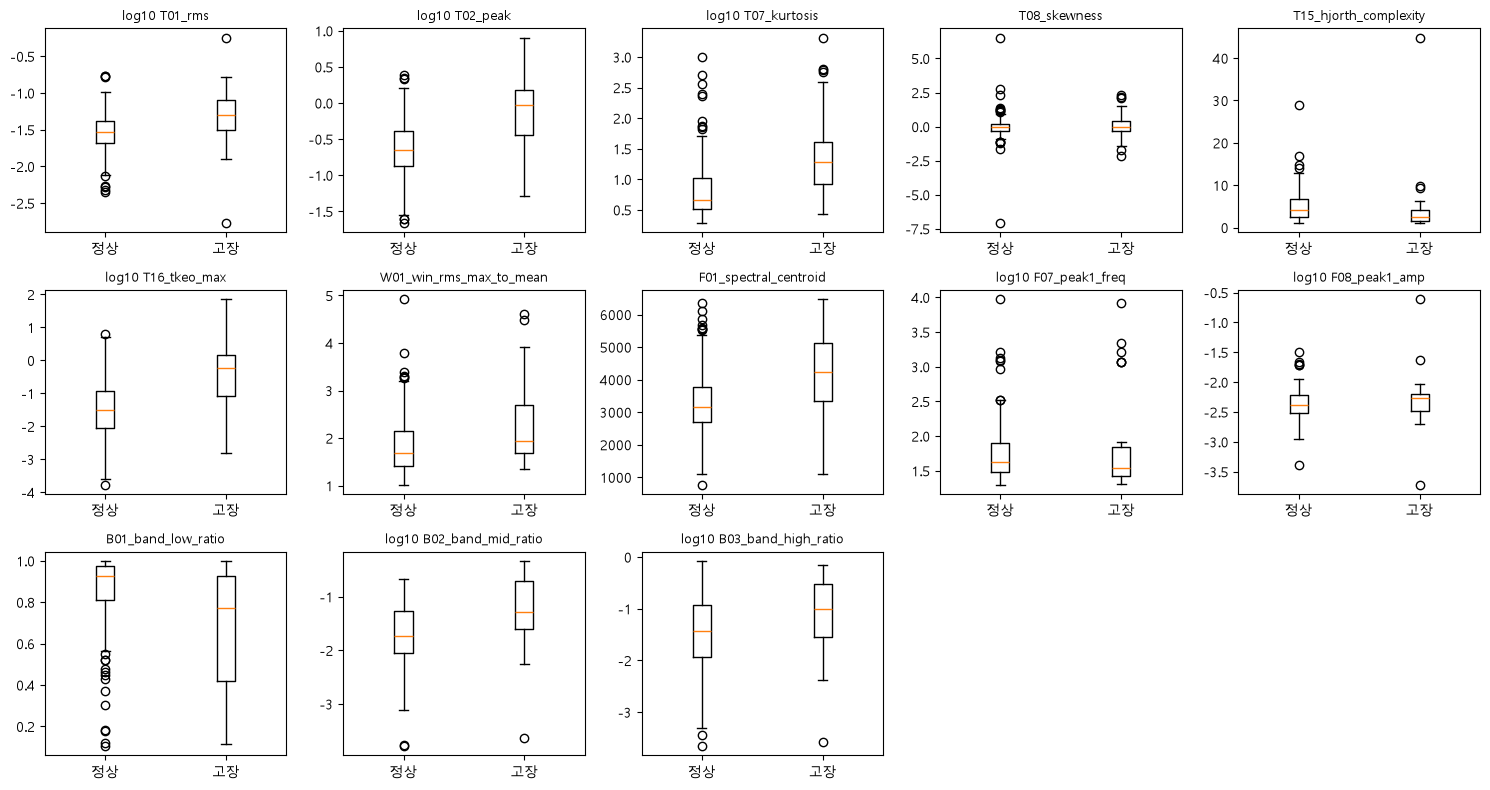

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for ax, col in zip(axes.ravel(), F.columns):
    v = F[col]
    title = col
    if v.min() > 0 and v.max() / v.min() > 100:
        v, title = np.log10(v), f"log10 {col}"  # 값 범위가 넓으면 로그를 취해 그림
    ax.boxplot([v[y == 0], v[y == 1]], tick_labels=["정상", "고장"])
    ax.set_title(title, fontsize=9)
for ax in axes.ravel()[len(F.columns):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. 피처 간 상관 (정상 120개만)

|r| ≥ 0.85 쌍은 정보가 겹친다 (`pipeline.md` 상관 정리 기준). 정상만 쓰는 이유: 고장 때문에 함께 커지는 '클래스 차이'가 상관으로 섞이지 않게

In [5]:
corr = F[y == 0].corr(method="spearman")
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(F.columns) for b in F.columns[i + 1:]
         if abs(corr.loc[a, b]) >= 0.85]
print("|r| ≥ 0.85 쌍 (Spearman, 정상만):")
for a, b, r in sorted(pairs, key=lambda p: -abs(p[2])):
    print(f"  {a} ~ {b}: {r:.2f}")

|r| ≥ 0.85 쌍 (Spearman, 정상만):
  T15_hjorth_complexity ~ B01_band_low_ratio: 0.98
  B01_band_low_ratio ~ B03_band_high_ratio: -0.96
  T15_hjorth_complexity ~ B03_band_high_ratio: -0.94
  T02_peak ~ T16_tkeo_max: 0.90
  F01_spectral_centroid ~ B03_band_high_ratio: 0.86
